# Première expérience : les références sans transfert sur S1

**Objectif.** Faire tourner, sur le scénario S1 (Letter), les cinq références sans transfert déjà implémentées, et poser un premier regard critique sur les résultats : y a-t-il un vrai décalage entre source et cible ? Que vaut chaque référence ? Quel niveau une méthode de transfert devra-t-elle battre ?

**Ce que le notebook utilise.** Uniquement le code du paquet `transfer_forest` : le contrat (`Context`, `make_forest`), le chargeur de S1 et les cinq références (`Src`, `Tgt`, `Union`, `Union-P`, `Oracle`).

**Ce qui est provisoire.** Deux maillons du pipeline n'existent pas encore :
- le **tirage** (test, réserve, budgets emboîtés) est écrit ici en quelques lignes, en suivant le protocole ; il sera remplacé par le maillon protocole ;
- la **notation** se limite à la note principale de S1, le taux d'erreur ; les autres notes (BER, F1, log loss) viendront avec `evaluate`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from transfer_forest.contracts import Context, make_forest
from transfer_forest.data import load_scenarios
from transfer_forest.methods import METHODS, make_method

## 1. Le scénario S1

Letter : 20 000 lettres capitales décrites par 16 variables, 26 classes. Comme Segev et al. (2017), on coupe selon `x2bar`, la variance horizontale des pixels allumés : les lettres étroites ($x2bar \le 4$, la médiane) forment la source, les lettres étalées la cible.

In [2]:
[scn] = load_scenarios("S1")
print(f"source : {scn.n_S} exemples   cible : {len(scn.yt)} exemples   K = {scn.K}   d = {scn.d}")

source : 10822 exemples   cible : 9178 exemples   K = 26   d = 16


## 2. Le tirage (provisoire)

On suit le protocole :
- la cible est coupée une fois pour toutes en **test** (50 %, stratifié, graine fixe) et **réserve** ; le test ne sert qu'à noter ;
- pour chaque graine, la réserve est mélangée ; les $K$ premiers éléments couvrent les $K$ classes (sinon, à 1 %, il manque 2 à 5 lettres) ;
- le budget $p$ donne $n_T = \max(\mathrm{round}(p \cdot n_S),\, K)$ exemples étiquetés : les $n_T$ premiers de l'ordre. Les budgets sont donc **emboîtés**.

In [3]:
# Provisoire : ces constantes et ce tirage reviendront au contrat et au maillon protocole.
TEST_SEED, SEEDS, BUDGETS = 12345, range(20), (0.01, 0.02, 0.05, 0.10, 0.20)

reserve, test = train_test_split(np.arange(len(scn.yt)), test_size=scn.test_frac,
                                 stratify=scn.yt, random_state=TEST_SEED)
Xr, yr = scn.Xt[reserve], scn.yt[reserve]
X_test, y_test = scn.Xt[test], scn.yt[test]

def reserve_order(seed):
    """Ordre de la réserve pour une graine ; les K premiers éléments couvrent les K classes."""
    perm = np.random.default_rng(seed).permutation(len(yr))
    first = np.sort(np.unique(yr[perm], return_index=True)[1])   # 1re apparition de chaque classe
    return np.concatenate([perm[first], np.delete(perm, first)])

n_T = {p: max(round(p * scn.n_S), scn.K) for p in BUDGETS}
print(f"réserve : {len(yr)}   test : {len(y_test)}   budgets n_T : {list(n_T.values())}")

réserve : 4589   test : 4589   budgets n_T : [108, 216, 541, 1082, 2164]


## 3. Le décalage entre source et cible

Deux questions, mesurées sur la **réserve** (jamais sur le test) :
- **(a) les entrées changent-elles ?** Distribution de `x2bar`, puis, pour chaque variable, l'écart de moyennes standardisé
$$\mathrm{SMD}_j = \frac{\bar x^{T}_j - \bar x^{S}_j}{\sqrt{\big(s^{S\,2}_j + s^{T\,2}_j\big)/2}} ;$$
- **(b) les proportions de classes changent-elles ?** Pour chaque lettre, le rapport $\lambda_k = P_T(Y = k) / P_S(Y = k)$ (celui qu'utilise STRUT*) : $\lambda_k = 1$ si la lettre est aussi fréquente dans les deux domaines.

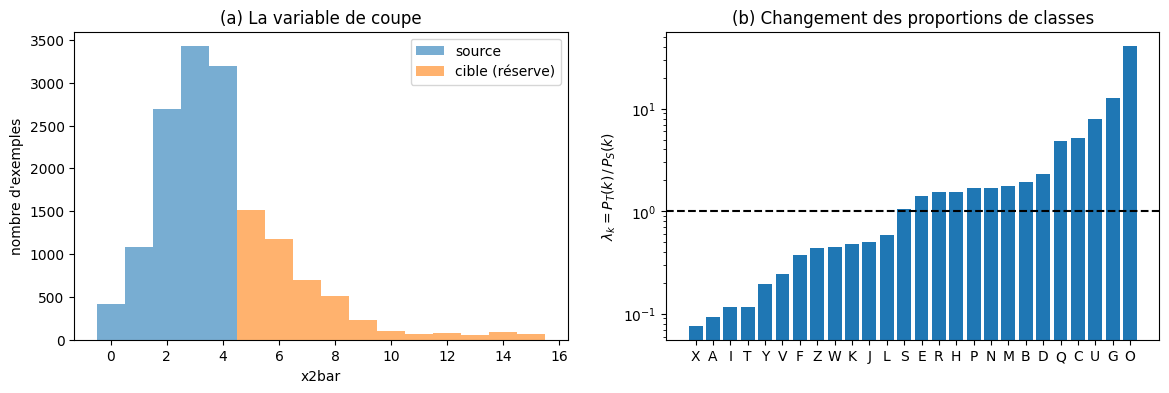

In [4]:
j = scn.params["split_feature_idx"]                                  # colonne de x2bar
lam = (np.bincount(yr) / len(yr)) / (np.bincount(scn.ys) / scn.n_S)  # P_T(k) / P_S(k)
rank = np.argsort(lam)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
bins = np.arange(17) - 0.5
ax1.hist(scn.Xs[:, j], bins, alpha=0.6, label="source")
ax1.hist(Xr[:, j], bins, alpha=0.6, label="cible (réserve)")
ax1.set(xlabel="x2bar", ylabel="nombre d'exemples", title="(a) La variable de coupe")
ax1.legend()
ax2.bar(np.array(scn.class_names)[rank], lam[rank])
ax2.axhline(1, color="k", ls="--")
ax2.set(yscale="log", ylabel=r"$\lambda_k = P_T(k)\,/\,P_S(k)$", title="(b) Changement des proportions de classes")
plt.show()

In [5]:
smd = (Xr.mean(0) - scn.Xs.mean(0)) / np.sqrt((scn.Xs.var(0) + Xr.var(0)) / 2)
pd.Series(smd, index=scn.feature_names).sort_values(key=abs, ascending=False).head(6).round(2)

x2bar    2.31
xybar   -0.66
yegvx    0.33
xy2br    0.30
y-ege    0.26
x-bar   -0.21
dtype: float64

### Ce que l'on observe

**Les entrées changent.** Par construction, les deux domaines n'ont aucune valeur de `x2bar` en commun : $x2bar \le 4$ dans la source, $\ge 5$ dans la cible ($\mathrm{SMD} = 2{,}31$). Le décalage déborde un peu sur une variable liée, `xybar` ($-0{,}66$) ; toutes les autres restent sous $0{,}35$ en valeur absolue. C'est un **décalage des covariables** concentré sur une direction de l'espace.

**Les proportions de classes changent aussi, et fortement.** $\lambda_k$ va de $0{,}08$ (X) à $41$ (O) : certaines lettres sont naturellement étalées (O, G, U, C, Q sont presque toutes dans la cible), d'autres naturellement étroites (X, A, I, T presque toutes dans la source). La source ne contient par exemple qu'une vingtaine de O. La coupe sur `x2bar` crée donc, en plus, un **décalage des classes** : $P_S(Y) \ne P_T(Y)$.

> **Regard critique.** Le protocole présente S1 comme un décalage « des entrées ». C'est incomplet : S1 combine décalage des covariables et décalage des classes. Conséquence directe pour la suite : la note de méthodes prévoyait SER* $\approx$ SER et STRUT* $\approx$ STRUT sur Letter, supposé équilibré. Ce n'est pas acquis : la correction des proportions de STRUT* a précisément de quoi agir ici.

## 4. Faire tourner les références

Pour chaque graine : on apprend la forêt source (partagée par toutes les méthodes), puis, pour chaque budget, on construit le `Context` et on fait apprendre et prédire chaque méthode. Src et Oracle ne dépendent pas du budget : une seule exécution par graine. Au total $20 \times (2 + 3 \times 5) = 340$ expériences, quelques minutes de calcul.

In [6]:
def error(name, ctx):
    P = make_method(name).fit(ctx).predict_proba(X_test)
    return (P.argmax(axis=1) != y_test).mean()

rows = []
for seed in SEEDS:
    rf_src = make_forest(seed).fit(scn.Xs, scn.ys)
    order = reserve_order(seed)
    for p in BUDGETS:
        lab, unlab = order[:n_T[p]], order[n_T[p]:]
        ctx = Context(scn.Xs, scn.ys, Xr[lab], yr[lab], Xr[unlab], rf_src, scn.K, seed,
                      X_reserve=Xr, y_reserve=yr)
        for name, cls in METHODS.items():
            if cls.uses_budget or p == BUDGETS[0]:           # Src et Oracle : une fois par graine
                rows.append({"seed": seed, "n_T": n_T[p] if cls.uses_budget else None,
                             "method": name, "err": error(name, ctx)})
results = pd.DataFrame(rows)
print(len(results), "expériences")

340 expériences


## 5. Les résultats

Taux d'erreur sur le test cible, moyenne et écart type sur les 20 graines (`n_T` vide : Src et Oracle, indépendantes du budget).

In [7]:
results.groupby(["method", "n_T"], dropna=False)["err"].agg(["mean", "std"]).round(3)

mean    std
method  n_T                 
Oracle  NaN     0.059  0.002
Src     NaN     0.575  0.010
Tgt     108.0   0.406  0.020
        216.0   0.291  0.019
        541.0   0.189  0.012
        1082.0  0.134  0.008
        2164.0  0.094  0.004
Union   108.0   0.384  0.014
        216.0   0.294  0.014
        541.0   0.185  0.008
        1082.0  0.124  0.007
        2164.0  0.081  0.004
Union-P 108.0   0.314  0.021
        216.0   0.229  0.019
        541.0   0.152  0.008
        1082.0  0.111  0.007
        2164.0  0.078  0.005

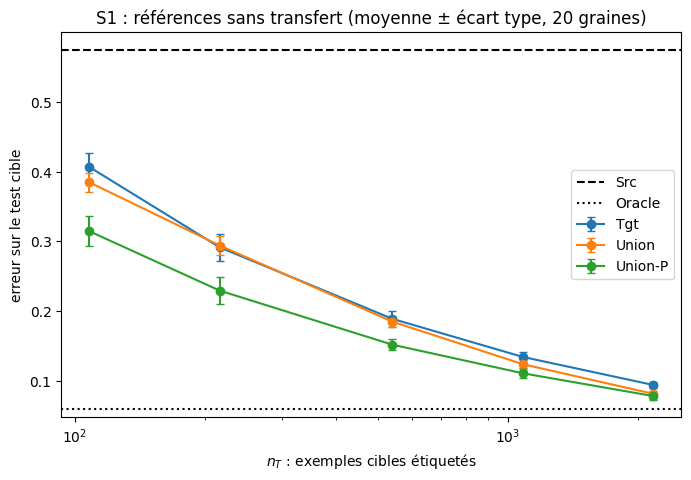

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in ["Tgt", "Union", "Union-P"]:
    curve = results[results.method == name].groupby("n_T")["err"]
    ax.errorbar(curve.mean().index, curve.mean(), yerr=curve.std(), marker="o", capsize=3, label=name)
for name, style in [("Src", "--"), ("Oracle", ":")]:
    ax.axhline(results.loc[results.method == name, "err"].mean(), color="k", ls=style, label=name)
ax.set(xscale="log", xlabel=r"$n_T$ : exemples cibles étiquetés", ylabel="erreur sur le test cible",
       title="S1 : références sans transfert (moyenne ± écart type, 20 graines)")
ax.legend()
plt.show()

### Lecture

| Référence | Erreur | Lecture |
|---|---|---|
| Src | $57{,}5\,\%$ ($\pm 1{,}0$) | la forêt source rate plus d'une lettre sur deux dans la cible |
| Oracle | $5{,}9\,\%$ ($\pm 0{,}2$) | avec toute la réserve étiquetée, la cible est facile |
| Tgt | de $40{,}6\,\%$ ($n_T = 108$) à $9{,}4\,\%$ ($n_T = 2\,164$) | s'améliore régulièrement avec le budget |
| Union | de $38{,}4\,\%$ à $8{,}1\,\%$ | à peine mieux que Tgt |
| Union-P | de $31{,}4\,\%$ à $7{,}8\,\%$ | la meilleure référence à tous les budgets |

**Le décalage est réel et massif.** La même forêt source fait $4{,}4\,\%$ d'erreur sur la source (erreur hors sac, section 7) et $57{,}5\,\%$ sur la cible : l'écart de domaine est d'environ $53$ points. Ce n'est pas la cible qui est difficile : Oracle y atteint $5{,}9\,\%$, du même ordre que la source. C'est bien le **décalage** qui fait échouer Src.

**Les ordres de grandeur sont plausibles.** Le guide cite pour Letter, d'après Segev : Src $\approx 66\,\%$, Tgt $\approx 19\,\%$. Notre Tgt fait $18{,}9\,\%$ à $n_T = 541$ (5 %) : ce chiffre de Segev correspond peut-être à ce budget, **à vérifier dans l'article**. Notre Src est plus basse de 8 points : l'écart reste à comprendre (découpage du test, réglages des forêts).

## 6. Comparaisons appariées

Le protocole compare les méthodes **graine par graine** : à graine et budget égaux, elles ont reçu exactement les mêmes exemples. On calcule, pour chaque budget, la proportion des 20 graines où une référence fait mieux que Tgt, et le gain moyen en points d'erreur, $\bar G(p) = \frac{1}{R}\sum_{s=1}^{R} \big(\mathrm{Err}_{\mathrm{Tgt}}(s,p) - \mathrm{Err}_m(s,p)\big)$.

In [9]:
err = results.pivot_table(index=["seed", "n_T"], columns="method", values="err")
pd.DataFrame({
    "Union-P bat Tgt": (err["Union-P"] < err["Tgt"]).groupby("n_T").mean(),
    "Union bat Tgt": (err["Union"] < err["Tgt"]).groupby("n_T").mean(),
    "gain Union-P (points)": 100 * (err["Tgt"] - err["Union-P"]).groupby("n_T").mean(),
    "gain Union (points)": 100 * (err["Tgt"] - err["Union"]).groupby("n_T").mean(),
}).round(2)

,Union-P bat Tgt,Union bat Tgt,gain Union-P (points),gain Union (points)
n_T,,,,
108.0,1.0,0.90,9.21,2.20
216.0,1.0,0.45,6.21,-0.26
541.0,1.0,0.60,3.70,0.40
1082.0,1.0,1.00,2.34,1.04
2164.0,1.0,1.00,1.59,1.27


### Lecture

**Union-P bat Tgt sur les 20 graines, à tous les budgets.** Le gain moyen décroît avec le budget : $9{,}2$ points à $n_T = 108$, puis $6{,}2$ ; $3{,}7$ ; $2{,}3$ ; $1{,}6$. C'est le profil attendu d'un transfert utile : la source compte surtout quand la cible est pauvre. À $n_T = 108$, Union-P ($31{,}4\,\%$) fait à peu près comme Tgt avec deux fois plus d'exemples ($29{,}1\,\%$ à $n_T = 216$) : environ **la moitié des annotations économisées**.

**Union n'apporte presque rien.** Gain moyen entre $-0{,}3$ et $+2{,}2$ points, et Union ne bat Tgt que sur 45 % des graines à $n_T = 216$. Explication : sans pondération, la source représente plus de 99 % des données à 1 % de budget ; la forêt apprend surtout la source. Rééquilibrer les masses, comme le fait Union-P,
$$\tfrac12\,\hat P_S + \tfrac12\,\hat P_T \quad\text{au lieu de}\quad \tfrac{n_S}{n_S + n_T}\,\hat P_S + \tfrac{n_T}{n_S + n_T}\,\hat P_T ,$$
change tout.

**La variabilité compte.** À petit budget, l'écart type de Tgt atteint 2 points, plus que certains écarts entre méthodes (Union contre Tgt). Seules les comparaisons appariées, puis le test de Wilcoxon prévu au protocole, permettront de conclure sur des écarts de cette taille.

## 7. Où Src se trompe-t-elle ?

Pour la graine 0 : l'erreur de la forêt source sur la source (hors sac) et sur la cible, puis son erreur lettre par lettre, mise en regard du changement de proportion $\lambda_k$.

Src, erreur sur la source (hors sac) : 0.044   sur la cible : 0.576


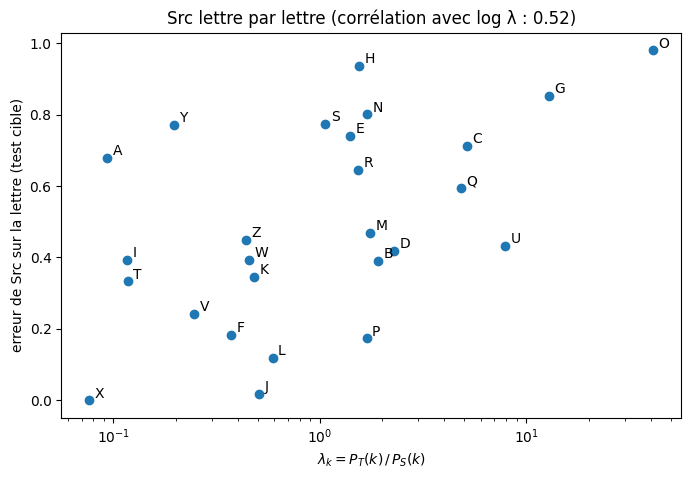

In [10]:
rf_src = make_forest(0).set_params(oob_score=True).fit(scn.Xs, scn.ys)
pred = rf_src.predict(X_test)
err_k = np.array([(pred[y_test == k] != k).mean() for k in range(scn.K)])
print(f"Src, erreur sur la source (hors sac) : {1 - rf_src.oob_score_:.3f}   sur la cible : {(pred != y_test).mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(lam, err_k)
for k, name in enumerate(scn.class_names):
    ax.annotate(name, (lam[k], err_k[k]), xytext=(4, 2), textcoords="offset points")
ax.set(xscale="log", xlabel=r"$\lambda_k = P_T(k)\,/\,P_S(k)$", ylabel="erreur de Src sur la lettre (test cible)",
       title=f"Src lettre par lettre (corrélation avec log λ : {np.corrcoef(np.log(lam), err_k)[0, 1]:.2f})")
plt.show()

### Lecture

L'erreur de Src varie énormément d'une lettre à l'autre : de $0\,\%$ (X) et $2\,\%$ (J) à $85\,\%$ (G), $94\,\%$ (H) et $98\,\%$ (O). Elle est nettement liée au changement de proportion (corrélation de $0{,}52$ avec $\log \lambda_k$) : les lettres presque absentes de la source, comme O ou G, sont celles que la forêt source ne sait pas reconnaître une fois étalées.

Mais la proportion n'explique pas tout : H est aussi fréquente dans les deux domaines ($\lambda \approx 1{,}5$) et pourtant ratée à $94\,\%$. De même, A et Y, presque absentes de la cible ($\lambda < 0{,}2$), y sont ratées à $68\,\%$ et $77\,\%$. Pour ces lettres, c'est l'**apparence** qui change quand la lettre s'élargit : la règle $P(Y \mid X)$ elle-même se déplace. S1 mêle donc les trois formes de décalage de l'état de l'art : covariables, classes et, localement, concept.

## 8. Bilan et regard critique

1. **Le décalage de S1 est réel et massif** : environ 53 points d'écart de domaine. Ce n'est pas la tâche cible qui est difficile (Oracle : $5{,}9\,\%$), c'est le passage d'un domaine à l'autre.
2. **Ce décalage est mixte** : covariables (supports disjoints sur `x2bar`), classes ($\lambda_k$ de $0{,}08$ à $41$) et, pour certaines lettres comme H, concept. La description du protocole (« décalage des entrées ») est à compléter, et SER*/STRUT* méritent d'être testés sur S1.
3. **Union-P est une référence forte** : meilleure que Tgt sur 20 graines sur 20, à tous les budgets, avec environ moitié moins d'annotations à petit budget. La barre est haute : **une méthode de transfert devra battre Union-P, pas seulement Tgt**.
4. **Conséquence pour le protocole** : le gain $G_{\mathrm{ref}} = \min(\mathrm{Err}_{\mathrm{Src}}, \mathrm{Err}_{\mathrm{Tgt}}, \mathrm{Err}_{\mathrm{Union}}) - \mathrm{Err}_m$ ne contient pas Union-P, qui est ici la meilleure référence. Une méthode pourrait afficher un gain positif tout en faisant moins bien qu'une simple repondération. **Il faudrait ajouter Union-P à ce minimum.**
5. **La cible est déséquilibrée** : de 47 à plus de 700 exemples par lettre. Le taux d'erreur reste la note principale (comme Segev), mais la BER, prévue en note secondaire, sera utile pour vérifier que les gains ne portent pas que sur les lettres fréquentes.

**Limites de cette première expérience.** Tirage et notation provisoires, codés dans ce notebook ; un seul découpage test/réserve ; hyperparamètres par défaut ; pas encore de test statistique. Les chiffres de Segev restent à vérifier dans l'article (budget correspondant, écart de 8 points sur Src).